# Assembly and annotation of Beringian mitogenomes

-----
| Name | Date | 
| - | - |
| Keiler Collier | 10 July 2026 |
-----

## 1 - Introduction

A main finding in [Collier et al. 2025](https://peerj.com/articles/20675/) was pairwise divergence metrics between sets of Arctic birds.

## 2 - Methods

### Assembly and annotation

To assemble reference-free mitogenomes, we started with 422 individuals in [Table S1](../table_S1.tsv).
Raw data was found for 421 individuals - *Numenius phaeopus variegatus* UAM 14228 / TB1364 was not found and not assembled.

Using an OSX laptop, we initially ran [`mitoz`](https://github.com/linzhi2013/MitoZ) on all samples using the `run` subcommand, which attempts to assemble and annotate each individual.
Because the default assembler in `mitoz`, [`MEGAHIT`](https://github.com/voutcn/MEGAHIT), fails in an OSX environment, we specified that `mitoz` prefer [`spades`](https://github.com/ablab/spades) for the assembly step.
Because `spades` is computationally inefficient for large numbers of reads, we capped the number of input sequences at 1.5 million, using [`seqkit`](https://github.com/shenwei356/seqkit) to subsample fasta files over that cap.

We then referenced annotation stats from the `summary.txt` file produced by `mitoz`, and recorded the length of each assembly, their circularity, and the numbers of protein-coding genes, tRNAs, and rRNAs.
We additionally recorded whether or not the ND2 gene (relevant for Table 5 of Collier et al. 2025) was present in each assembly.
If no annotations were found in `summary.txt` (0 genes found), we scored the assembly as a failure.
Assemblies which contained 1-37 genes were considered partial successes, and assemblies with 37+ were considered complete.

When `mitoz` failed to produce a assembly with at least one gene, we ran the data through a second assembler, [`NOVOPlasty`](https://github.com/ndierckx/NOVOPlasty).
Because `NOVOPlasty` uses an assembler which does not require a Unix environment, we did not encounter the performance problems that required subsampling, as in `mitoz`.
However, `NOVOPlasty` requires a seed sequence from a relatively closely-related mitochondrion to assemble mitogenomes.
We used a [Zebra Finch](https://www.ncbi.nlm.nih.gov/nucleotide/NC_007897.1) (*Taeniopygia guttata*) mitogenome, housed on GenBank as GenBank ID NC_007897.1.

[Prior experimentation](mtDNA_assembly_protocol_testing.ipynb) has showed that assembly with NOVOplasty with Passerine-derived data does not adversely affect the assembly rate of other orders within the data set (eg, Anseriformes or Charadriiformes).
Because `NOVOPlasty` does not annotate, putative assemblies were characterized using the `mitoz annotate` subcommand.
Summary statistics were collected for NOVOPlasty-derived mitogenomes identically to the `mitoz` genomes above.

### Whole genome alignments

### ND2 alignments

### Pairwise $D_A$ assessment

## 3 - Results

### Alignment and annotation

Of 422 individuals, we produced 326 successful mitogenomic assemblies, with 77.3% of the dataset (326/422) showing at least one annotated gene.
Of these assemblies, 222 or 68.1% (222/326) were produced by `mitoz`, and an additional 104 or 31.9% (104/326) were produced by `NOVOPlasty`.

'Complete' (having 37+ genes) assemblies represented roughly half (50.6%; 165/326) of the successful assemblies, although in 28 cases (8.6%, 28/326), genes were found to be duplicated.
The ND2 gene was found in 231 assemblies, 71.1% (231/326) of successful assemblies, and 54.7% (231/422) of assemblies overall.

The taxonomic spread of successful and partial assemblies assemblies was biased towards birds found in [Mclaughlin et al. 2020](https://onlinelibrary.wiley.com/doi/full/10.1111/mec.15574) (Figure 1).
ND2 presence/absence metrics broadly track rates of 'complete' mitogenome assemblies (Figure 2).

In [73]:
import pandas as pd
df=pd.read_csv('../mitogenome_assembly_results.csv', header=0)

/var/folders/9f/qg08kr_s3tv4cyjy6k2gmkth0000gn/T/ipykernel_68195/1740781994.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


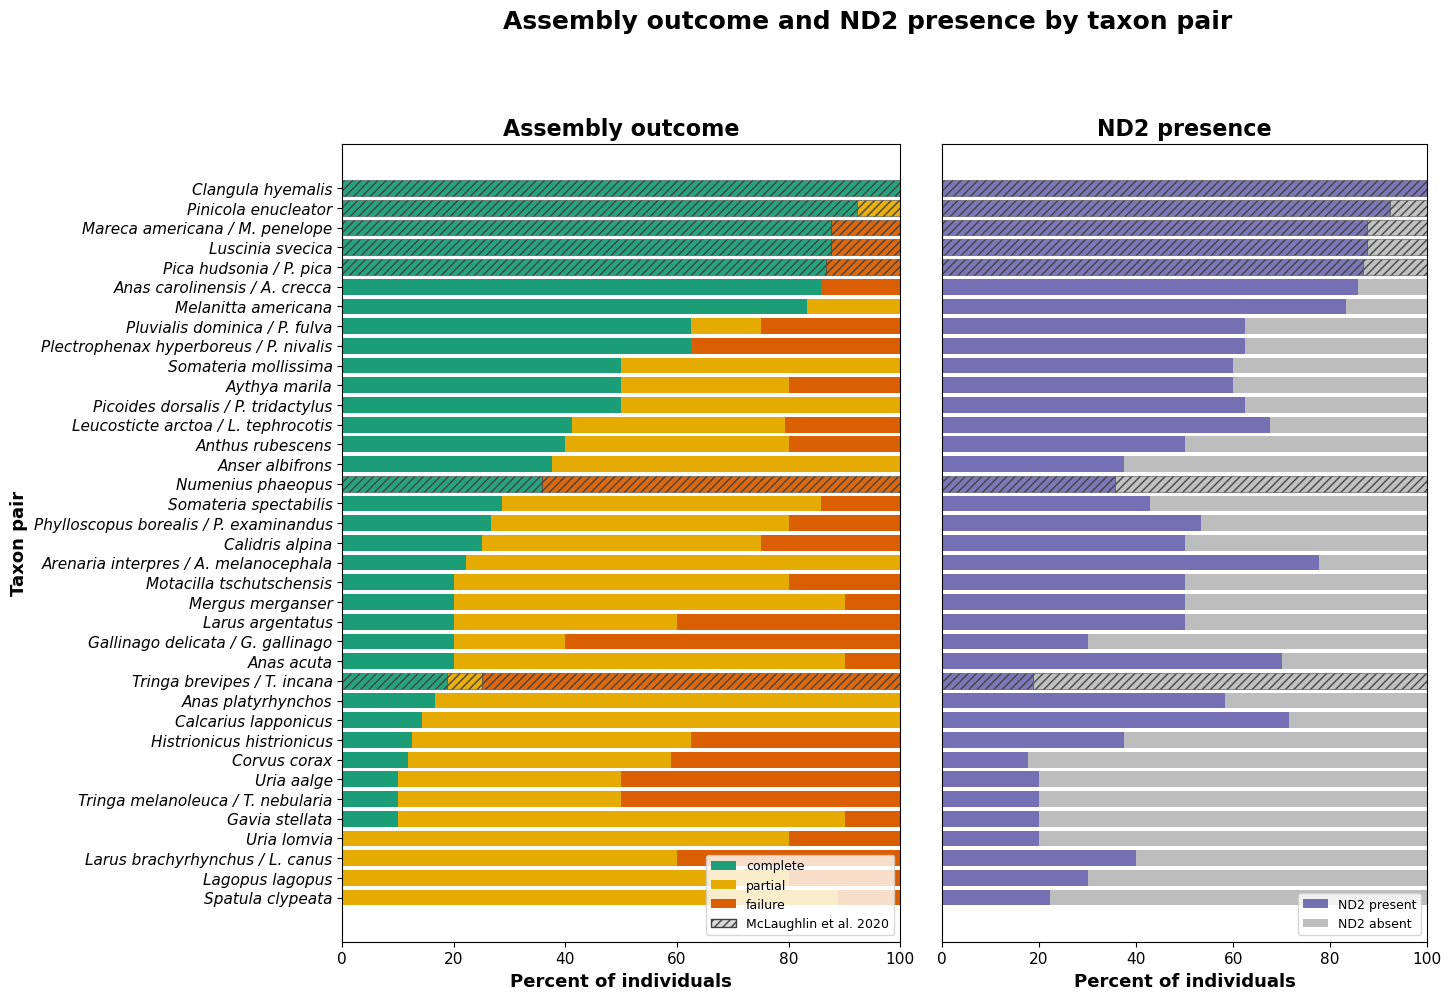

In [75]:
RUN_FIGS=True
if RUN_FIGS:
    # Horizontal stacked bar chart: assembly outcomes (left) and ND2 presence (right)
    import numpy as np
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    
    # Manual display names for y-axis labels (CSV taxon_pair -> plot label).
    # Leave unlisted keys unchanged.
    TAXON_PAIR_LABELS = {
        "Anas acuta": "Anas acuta",
        "Anas c": "Anas carolinensis / A. crecca",
        "Anas p": "Anas platyrhynchos",
        "Anser": "Anser albifrons",
        "Anthus": "Anthus rubescens",
        "Arenaria": "Arenaria interpres / A. melanocephala",
        "Aythya": "Aythya marila",
        "Calcarius": "Calcarius lapponicus",
        "Calidris": "Calidris alpina",
        "Clangula": "Clangula hyemalis",
        "Corvus": "Corvus corax",
        "Gallinago": "Gallinago delicata / G. gallinago",
        "Gavia": "Gavia stellata",
        "Histrionicus": "Histrionicus histrionicus",
        "Lagopus": "Lagopus lagopus",
        "Larus a": "Larus argentatus",
        "Larus c": "Larus brachyrhynchus / L. canus",
        "Leucosticte": "Leucosticte arctoa / L. tephrocotis",
        "Luscinia": "Luscinia svecica",
        "Mareca": "Mareca americana / M. penelope",
        "Melanitta": "Melanitta americana",
        "Mergus": "Mergus merganser",
        "Motacilla": "Motacilla tschutschensis",
        "Numenius": "Numenius phaeopus",
        "Phylloscopus": "Phylloscopus borealis / P. examinandus",
        "Pica": "Pica hudsonia / P. pica",
        "Picoides": "Picoides dorsalis / P. tridactylus",
        "Pinicola": "Pinicola enucleator",
        "Plectrophenax": "Plectrophenax hyperboreus / P. nivalis",
        "Pluvialis df": "Pluvialis dominica / P. fulva",
        "Somateria m": "Somateria mollissima",
        "Somateria s": "Somateria spectabilis",
        "Spatula": "Spatula clypeata",
        "Tringa bi": "Tringa brevipes / T. incana",
        "Tringa nm": "Tringa melanoleuca / T. nebularia",
        "Uria a": "Uria aalge",
        "Uria l": "Uria lomvia",
    }
    
    
    def _apply_mclaughlin_hatch(bars, is_mclaughlin):
        for bar, is_m in zip(bars, is_mclaughlin):
            if is_m:
                bar.set_hatch("////")
                bar.set_edgecolor("0.25")
                bar.set_linewidth(0.4)
                bar.set_alpha(0.95)
    
    
    work = df[df["taxon_pair"].notna() & (df["taxon_pair"].astype(str).str.strip() != "")].copy()
    # Normalize ND2_present in case it was read as string.
    work["nd2"] = work["ND2_present"].astype(str).str.lower().isin(["true", "1", "yes"])
    
    taxon_summary = (
        work.assign(
            is_failure=work["assembly_success"].eq("failure"),
            is_partial=work["assembly_success"].eq("partial"),
            is_complete=work["assembly_success"].eq("complete"),
            is_mclaughlin=work["data_origin"].eq("mclaughlin_2020"),
        )
        .groupby("taxon_pair", as_index=False)
        .agg(
            n=("directory_name", "size"),
            n_failure=("is_failure", "sum"),
            n_partial=("is_partial", "sum"),
            n_complete=("is_complete", "sum"),
            n_nd2=("nd2", "sum"),
            n_mclaughlin=("is_mclaughlin", "sum"),
        )
    )
    taxon_summary["failure_pct"] = taxon_summary["n_failure"] / taxon_summary["n"] * 100
    taxon_summary["partial_pct"] = taxon_summary["n_partial"] / taxon_summary["n"] * 100
    taxon_summary["complete_pct"] = taxon_summary["n_complete"] / taxon_summary["n"] * 100
    taxon_summary["nd2_present_pct"] = taxon_summary["n_nd2"] / taxon_summary["n"] * 100
    taxon_summary["nd2_absent_pct"] = 100 - taxon_summary["nd2_present_pct"]
    taxon_summary["taxon_label"] = taxon_summary["taxon_pair"].map(
        lambda x: TAXON_PAIR_LABELS.get(x, x)
    )
    taxon_summary["is_mclaughlin"] = taxon_summary["n_mclaughlin"] == taxon_summary["n"]
    
    plot_df = taxon_summary.sort_values(["complete_pct", "n"], ascending=[True, True]).reset_index(
        drop=True
    )
    
    y = np.arange(len(plot_df))
    fig, (ax_out, ax_nd2) = plt.subplots(
        1,
        2,
        figsize=(14, max(6, 0.28 * len(plot_df))),
        sharey=True,
        gridspec_kw={"width_ratios": [1.15, 1], "wspace": 0.08},
    )
    
    # Left: assembly outcome
    for col, color, left in [
        ("complete_pct", "#1b9e77", 0),
        ("partial_pct", "#e6ab02", plot_df["complete_pct"]),
        ("failure_pct", "#d95f02", plot_df["complete_pct"] + plot_df["partial_pct"]),
    ]:
        bars = ax_out.barh(y, plot_df[col], left=left, color=color, edgecolor="none")
        _apply_mclaughlin_hatch(bars, plot_df["is_mclaughlin"])
    
    ax_out.set_yticks(y)
    ax_out.set_yticklabels(plot_df["taxon_label"], fontstyle="italic", fontsize=11)
    ax_out.set_xlim(0, 100)
    ax_out.set_title("Assembly outcome", fontsize=16, fontweight="bold")
    ax_out.set_xlabel("Percent of individuals", fontsize=13, fontweight="bold")
    ax_out.set_ylabel("Taxon pair", fontsize=13, fontweight="bold")
    ax_out.tick_params(axis="x", labelsize=11)
    ax_out.legend(
        handles=[
            Patch(facecolor="#1b9e77", edgecolor="none", label="complete"),
            Patch(facecolor="#e6ab02", edgecolor="none", label="partial"),
            Patch(facecolor="#d95f02", edgecolor="none", label="failure"),
            Patch(
                facecolor="0.85",
                edgecolor="0.25",
                hatch="////",
                label="McLaughlin et al. 2020",
            ),
        ],
        loc="lower right",
        fontsize=9,
    )
    
    # Right: ND2 presence / absence
    bars_present = ax_nd2.barh(
        y, plot_df["nd2_present_pct"], color="#7570b3", edgecolor="none"
    )
    bars_absent = ax_nd2.barh(
        y,
        plot_df["nd2_absent_pct"],
        left=plot_df["nd2_present_pct"],
        color="#bdbdbd",
        edgecolor="none",
    )
    _apply_mclaughlin_hatch(bars_present, plot_df["is_mclaughlin"])
    _apply_mclaughlin_hatch(bars_absent, plot_df["is_mclaughlin"])
    
    ax_nd2.set_xlim(0, 100)
    ax_nd2.set_title("ND2 presence", fontsize=16, fontweight="bold")
    ax_nd2.set_xlabel("Percent of individuals", fontsize=13, fontweight="bold")
    ax_nd2.tick_params(axis="x", labelsize=11)
    ax_nd2.tick_params(axis="y", left=False, labelleft=False)
    ax_nd2.legend(
        handles=[
            Patch(facecolor="#7570b3", edgecolor="none", label="ND2 present"),
            Patch(facecolor="#bdbdbd", edgecolor="none", label="ND2 absent"),
        ],
        loc="lower right",
        fontsize=9,
    )
    
    fig.suptitle(
        "Assembly outcome and ND2 presence by taxon pair",
        fontsize=18,
        fontweight="bold",
        y=1.01,
    )
    plt.tight_layout()
    plt.show()
    
    taxon_summary.sort_values(["complete_pct", "n"], ascending=[False, False])[
        [
            "taxon_pair",
            "taxon_label",
            "n",
            "complete_pct",
            "partial_pct",
            "failure_pct",
            "nd2_present_pct",
            "is_mclaughlin",
        ]
    ].reset_index(drop=True)


## 4 - Discussion

### Assembly and annotation

`Mitoz` is broadly a better-performing assembler, producing nearly 70% of the successful assemblies in the study.
This is notable given the assembler's artificial handicap, as individuals with the highest amounts of data had to be severely subsampled to run in a reasonable amount of time.
It is likely that some of the cases where `NOVOPlasty` succeeded could've also been done by `mitoz`.

### Pairwise $D_A$ assessment

## 5 - Conclusion

## Assembly and annotation

`Mitoz` is a preferable assembler for mitogenomic data, and should be used over `NOVOPlasty`.